# Phân tích kết quả Benchmark

Biểu đồ cột thể hiện thời gian chạy (median) theo từng giá trị cutoff.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('../results/benchmark.csv')


df['data_label'] = df['data_type'] + '_' + df['data_size'].astype(str)

median_df = df.groupby(['algorithm', 'data_label', 'cutoff'])['time_ns'].median().reset_index()
median_df['time_ms'] = median_df['time_ns'] / 1_000_000

data_labels = sorted(median_df['data_label'].unique())
algorithms = sorted(median_df['algorithm'].unique())

## Biểu đồ cột: Thời gian chạy theo Cutoff

Mỗi biểu đồ dành riêng cho **1 thuật toán × 1 bộ dữ liệu**.

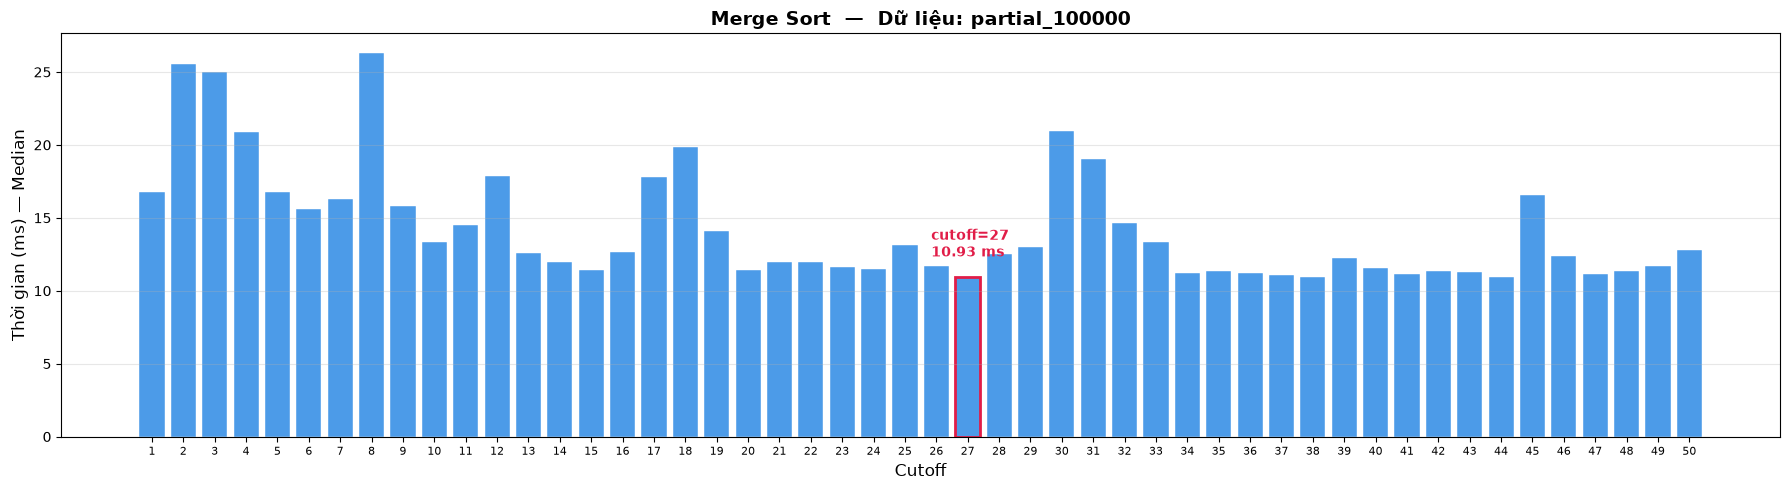

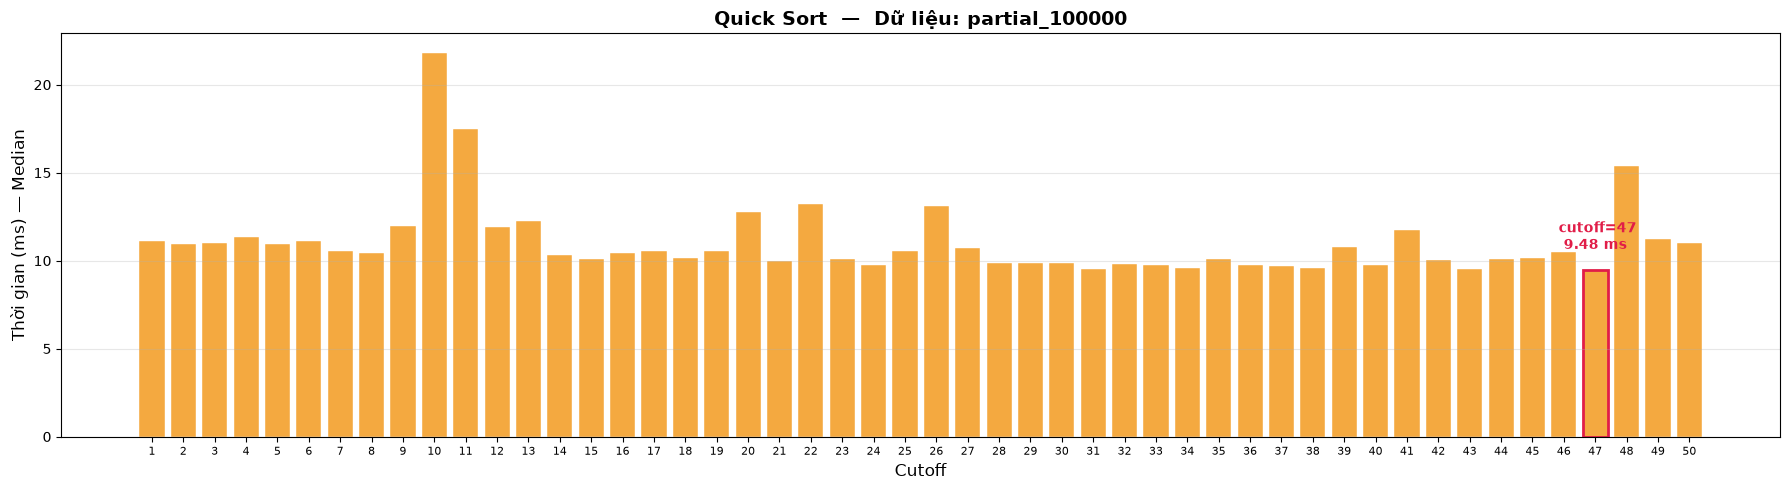

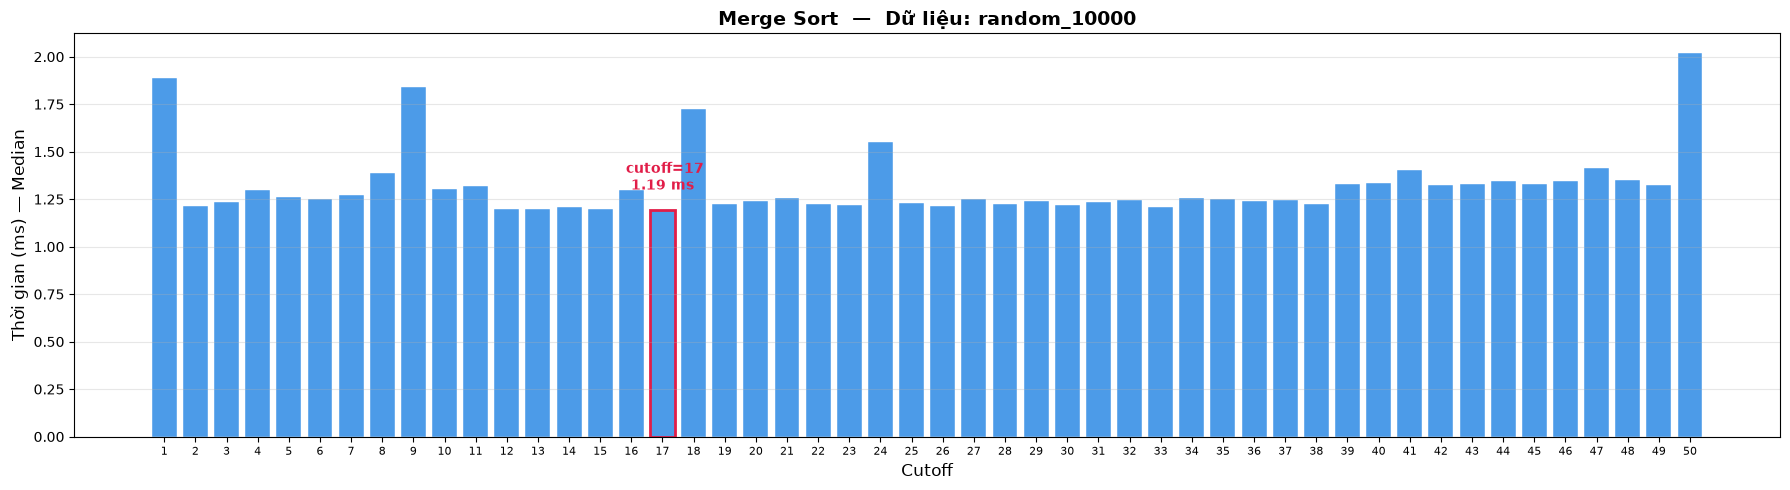

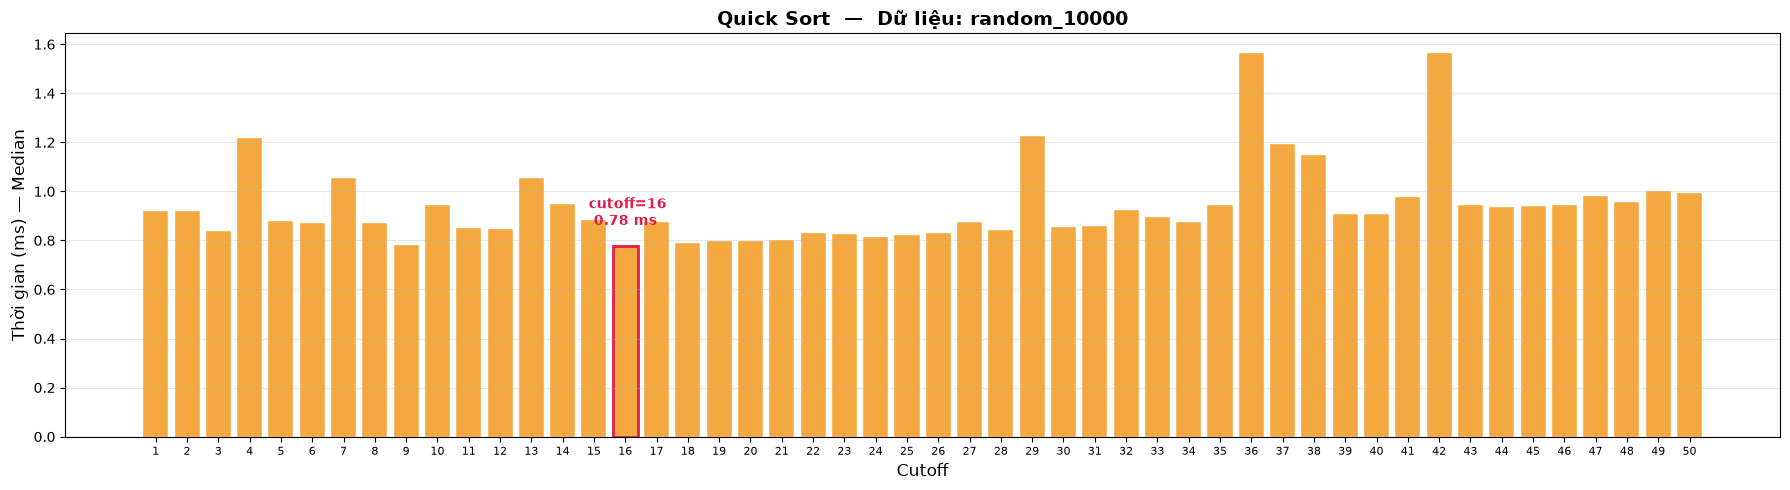

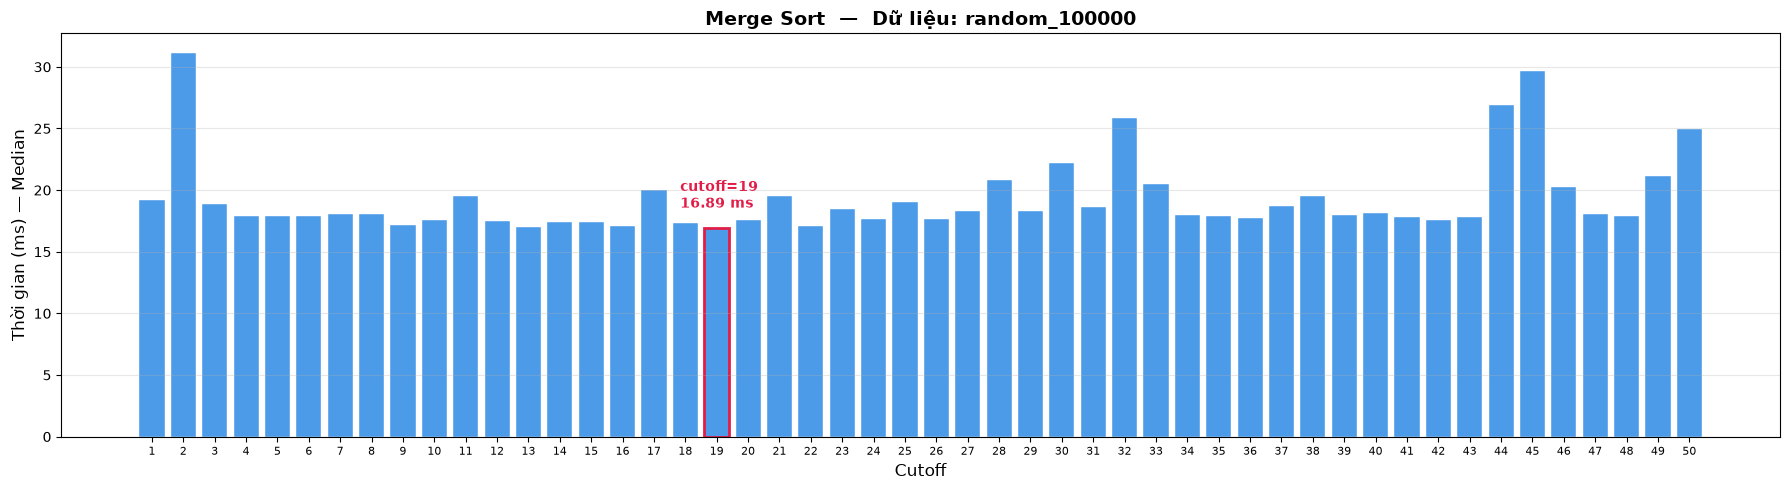

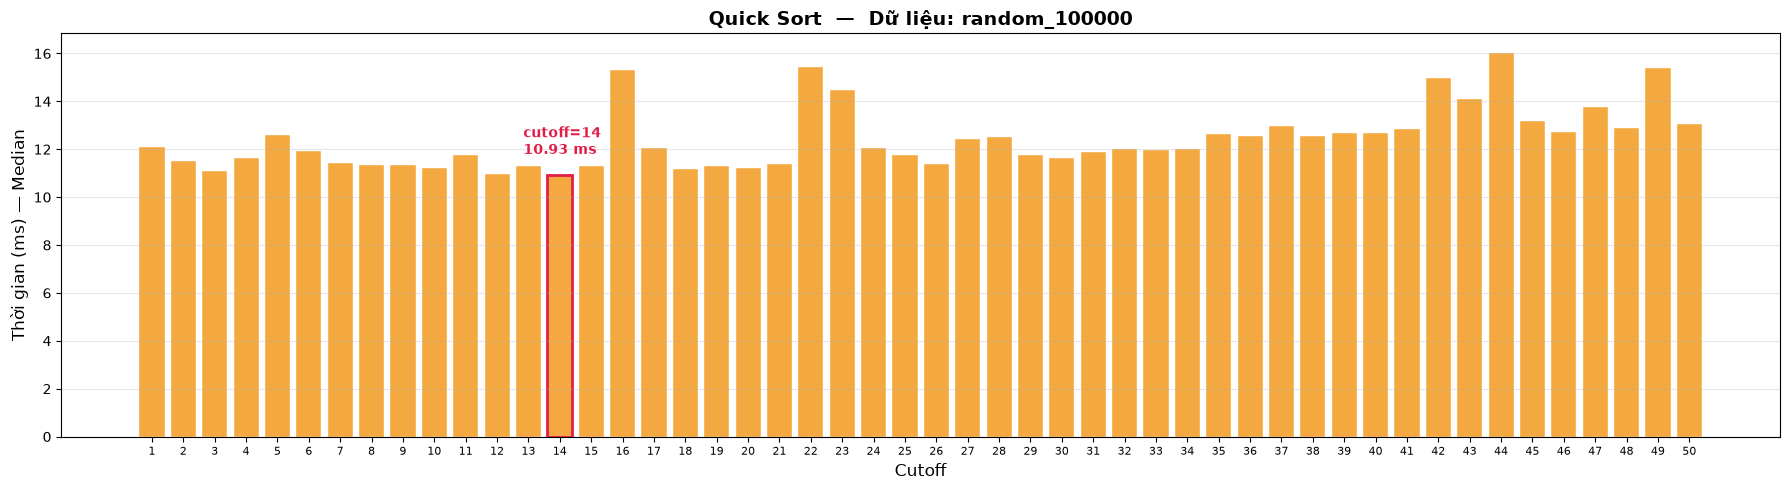

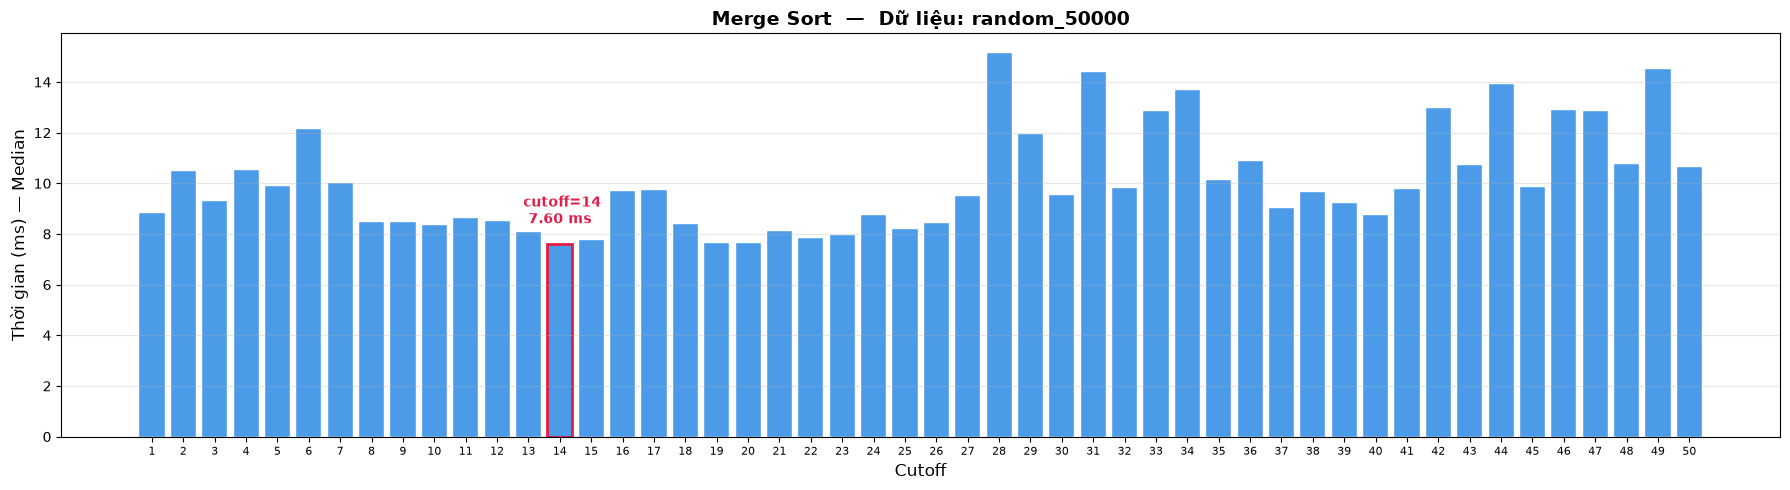

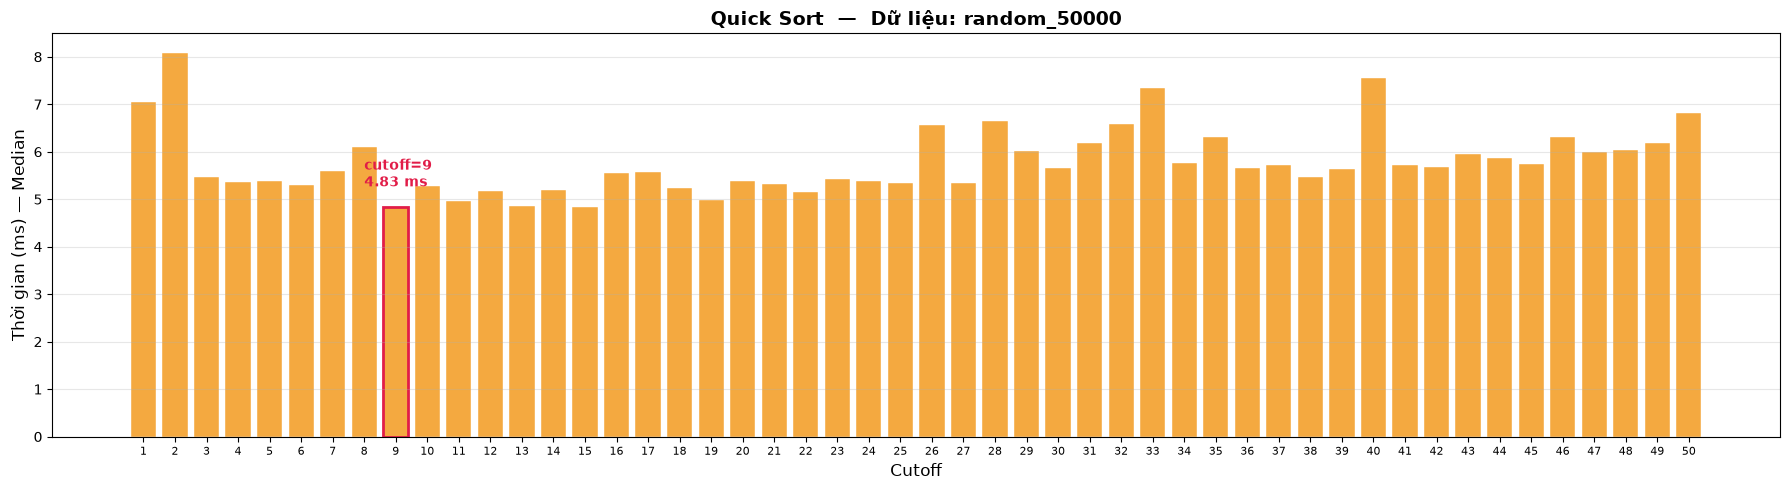

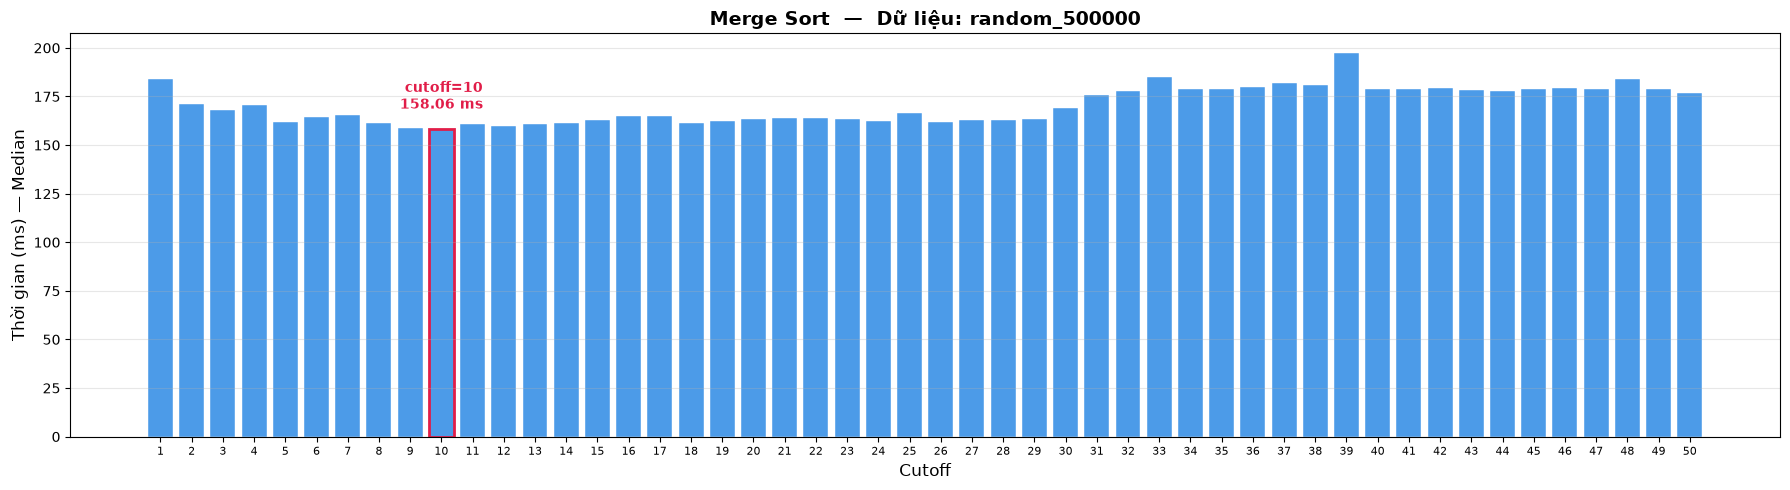

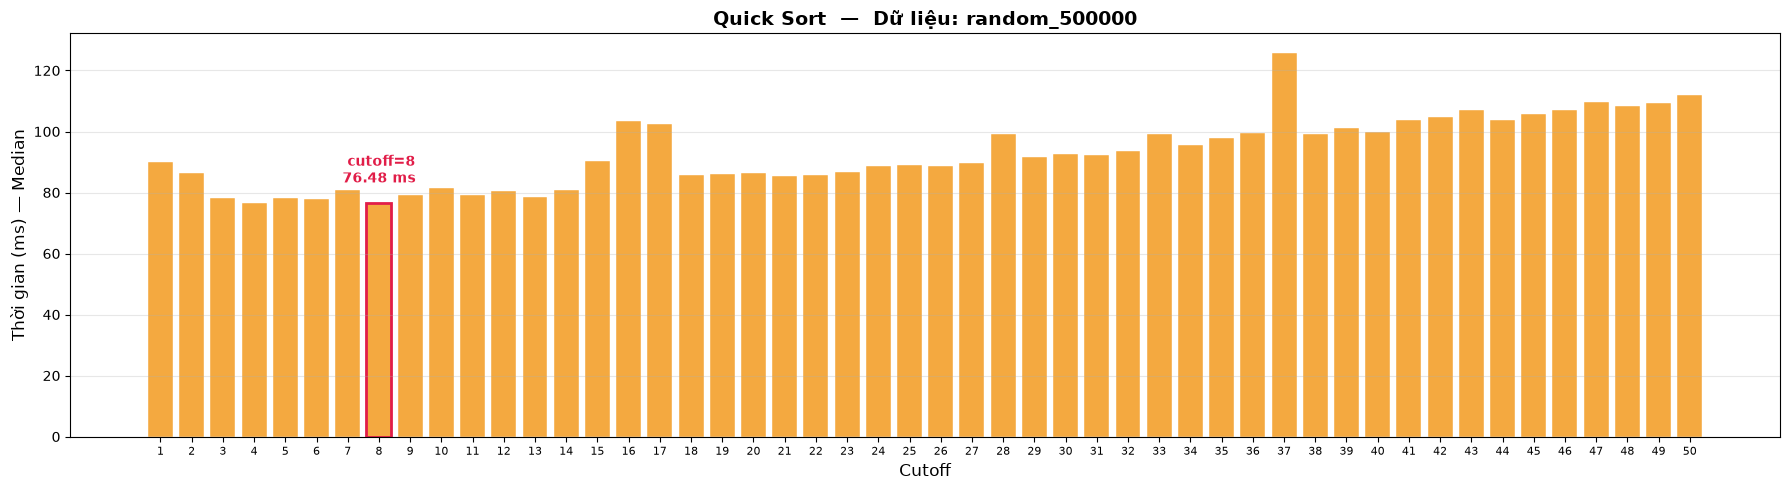

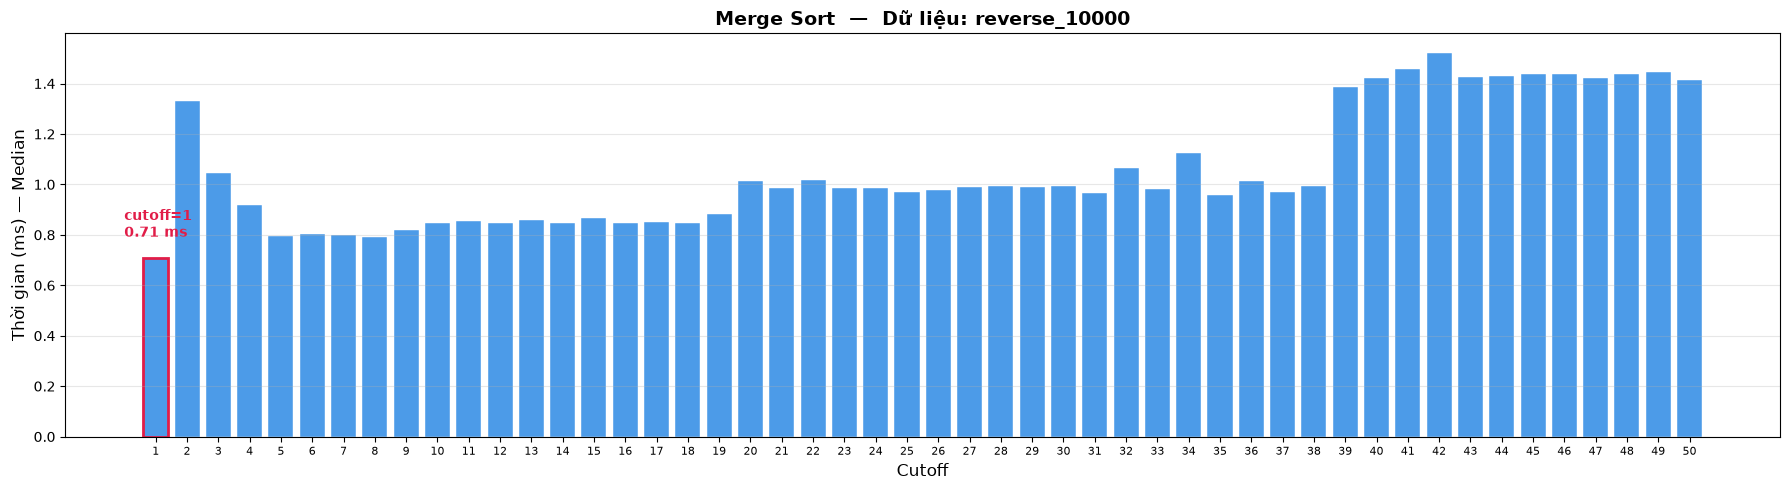

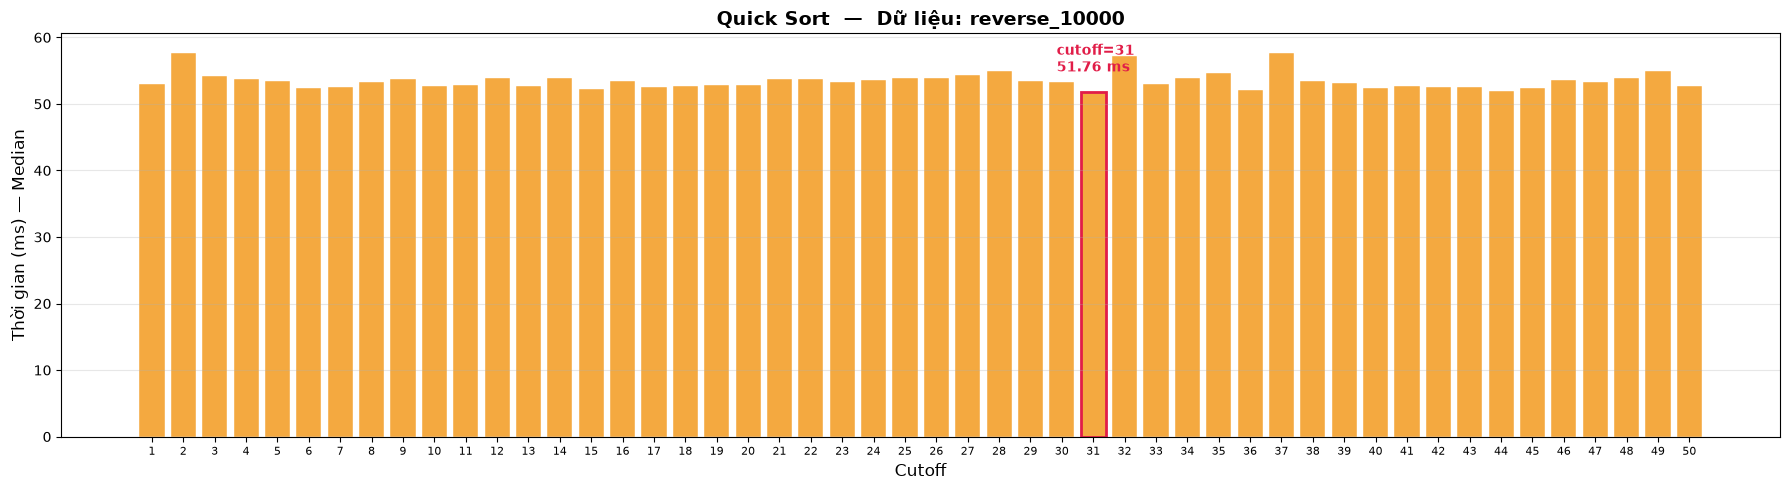

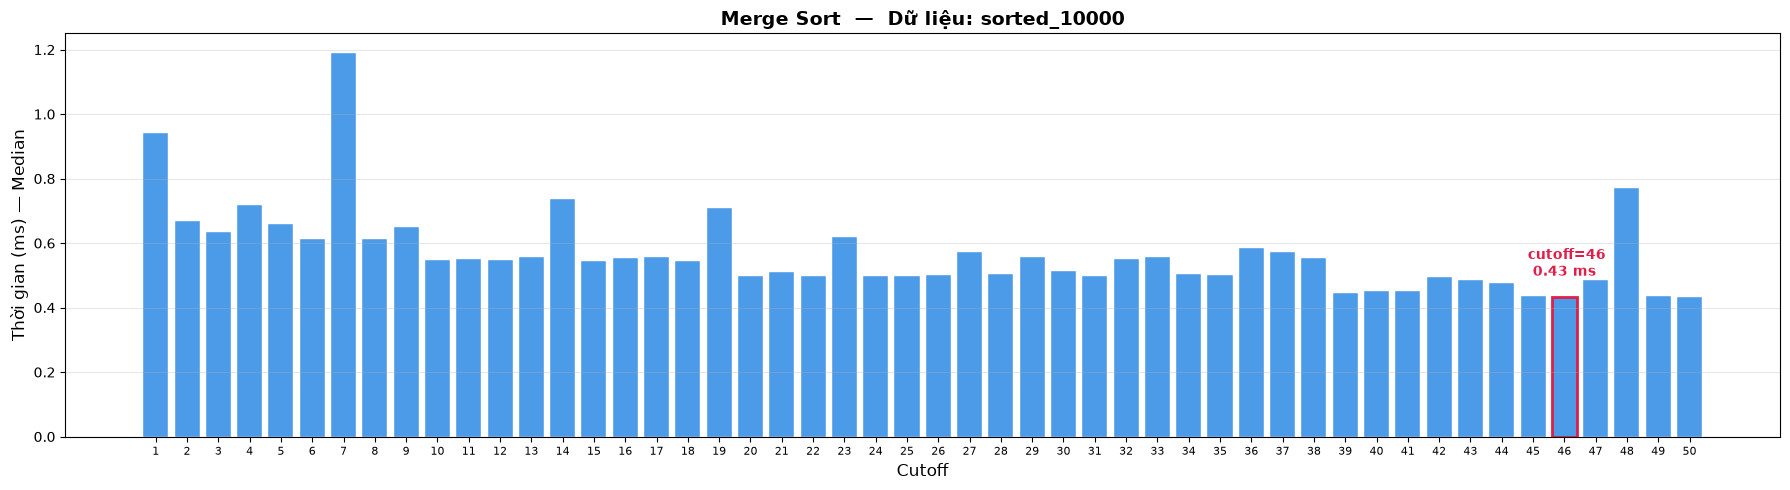

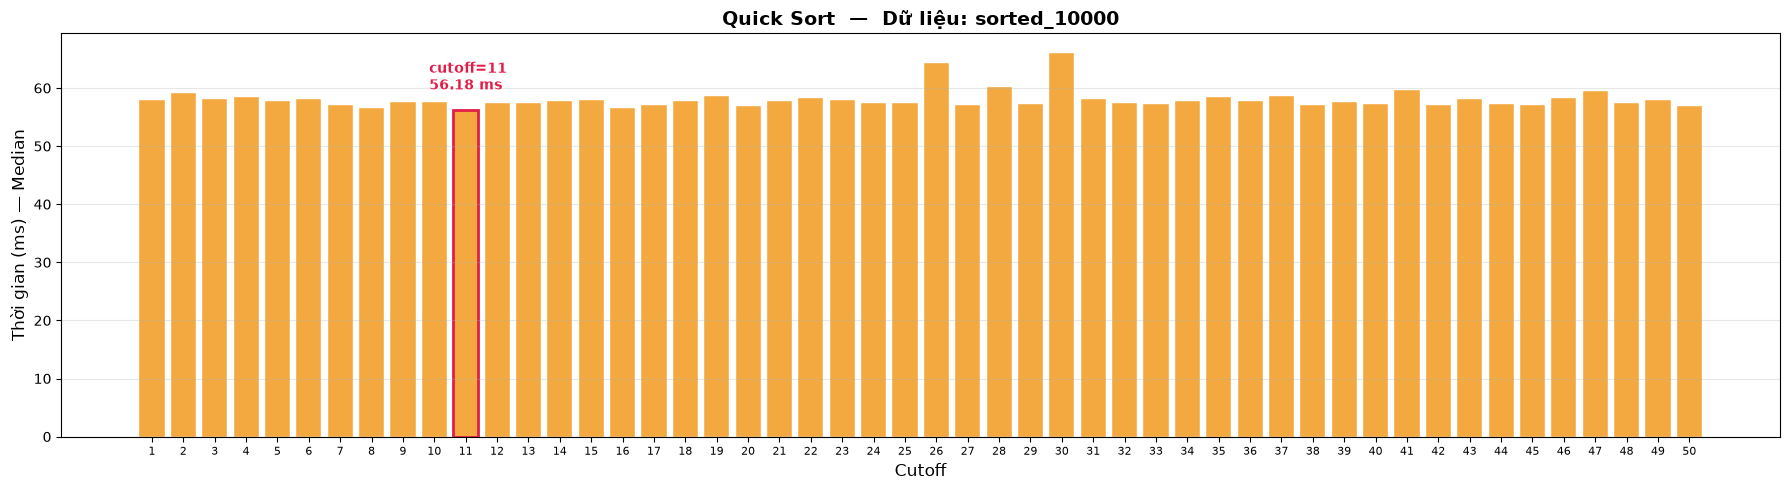

In [ ]:
algo_colors = {'merge_sort': '#4C9BE8', 'quick_sort': '#F4A940'}
algo_names = {'merge_sort': 'Merge Sort', 'quick_sort': 'Quick Sort'}

for label in data_labels:
    for algo in algorithms:
        subset = median_df[(median_df['data_label'] == label) & (median_df['algorithm'] == algo)]
        subset = subset.sort_values('cutoff')
        if subset.empty:
            continue

        cutoffs = subset['cutoff'].values
        times = subset['time_ms'].values
        x = np.arange(len(cutoffs))
        color = algo_colors[algo]

        fig, ax = plt.subplots(figsize=(18, 5))
        bars = ax.bar(x, times, color=color, edgecolor='white', linewidth=0.3)

        # Đánh dấu cutoff tối ưu
        best_idx = np.argmin(times)
        bars[best_idx].set_edgecolor('#E11D48')
        bars[best_idx].set_linewidth(2)
        ax.annotate(f' cutoff={cutoffs[best_idx]}\n{times[best_idx]:.2f} ms',
                    xy=(best_idx, times[best_idx]),
                    xytext=(0, 15), textcoords='offset points',
                    ha='center', fontsize=10, fontweight='bold', color='#E11D48')

        ax.set_xlabel('Cutoff', fontsize=12)
        ax.set_ylabel('Thời gian (ms) — Median', fontsize=12)
        ax.set_title(f'{algo_names[algo]}  —  Dữ liệu: {label}', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(cutoffs, fontsize=8)
        ax.grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.show()
        print()

## Bảng tổng hợp Cutoff tối ưu

In [9]:
# Tìm cutoff cho thời gian median nhỏ nhất
best = median_df.loc[median_df.groupby(['algorithm', 'data_label'])['time_ms'].idxmin()]
best = best[['algorithm', 'data_label', 'cutoff', 'time_ms']].sort_values(['data_label', 'algorithm'])
best.columns = ['Thuật toán', 'Dữ liệu', 'Cutoff tối ưu', 'Thời gian (ms)']
best['Thời gian (ms)'] = best['Thời gian (ms)'].round(2)
best = best.reset_index(drop=True)
display(best)

,Thuật toán,Dữ liệu,Cutoff tối ưu,Thời gian (ms)
0,merge_sort,partial_100000,27,10.93
1,quick_sort,partial_100000,47,9.48
2,merge_sort,random_10000,17,1.19
3,quick_sort,random_10000,16,0.78
4,merge_sort,random_100000,19,16.89
5,quick_sort,random_100000,14,10.93
6,merge_sort,random_50000,14,7.60
7,quick_sort,random_50000,9,4.83
8,merge_sort,random_500000,10,158.06
9,quick_sort,random_500000,8,76.48
